# FloodSense baseline model evaluation

Compare a prior-only dummy baseline with logistic regression using geographic and storm holdouts. The held-out 2019 Imelda test data is not loaded or used.

## 1. Load cleaned training data and evaluation functions

Load the cleaned 2015–2017 rows and reusable evaluation helpers. Model features exclude coordinates, storm identifiers, and the unverified imperviousness column.

In [1]:
import sys
from pathlib import Path

project_root = next(
    (parent for parent in (Path.cwd(), *Path.cwd().parents)
     if (parent / "src" / "config.py").is_file()),
    None,
)
if project_root is None:
    raise FileNotFoundError("Could not locate the FloodSense project root from the notebook working directory.")
sys.path.insert(0, str(project_root))

import pandas as pd
from IPython.display import display

from src.data import load_clean
from src.evaluate import (
    RESULTS_PATH,
    cross_validate,
    plot_confusion_matrix,
    plot_roc_pr,
    save_results,
)
from src.features import area_group_splits, leave_one_storm_out_splits
from src.models import MODEL_REGISTRY

df = load_clean()
print(f"Loaded {len(df):,} cleaned training rows.")


Cleaned training data shape: (66514, 14)
Missing values by column:
year                   0
storm_name             0
storm_date             0
lat                    0
lon                    0
weight                 0
elevation_m            0
slope_degrees          0
distance_to_bayou_m    0
paved_pct              0
land_cover_type        0
rainfall_inches        0
flooded                0
grid_id                0
Loaded 66,514 cleaned training rows.


**My observations:** _Note the dataset size and confirm the held-out test data was not used._

## 2. Build geographic and storm validation splits

Area GroupKFold measures performance in held-out places. Leave-one-storm-out uses all rows from the other two storms, including mostly known places, to measure generalization to a different storm. Each validation strategy is kept separate for its own comparison.

In [2]:
area_splits = list(area_group_splits(df, n_splits=5))
storm_splits = list(leave_one_storm_out_splits(df, drop_overlap_areas=False))
print(f"Area folds: {len(area_splits)}; storm folds: {len(storm_splits)}")


Area folds: 5; storm folds: 3


**My observations:** _Note how the geographic and storm split designs represent different kinds of generalization._

## 3. Cross-validate both baseline models

For every fold, a fresh pipeline is constructed and fitted only on its training rows. Preprocessing is therefore learned inside the fold, and validation probabilities are out-of-fold predictions. Save each model/split summary and its OOF predictions for later threshold selection or calibration.

In [3]:
evaluation_results = {}
for model_name, model_factory in MODEL_REGISTRY.items():
    for split_name, splits in (
        ("area_group", area_splits),
        ("leave_one_storm_out", storm_splits),
    ):
        summary_df, oof_df = cross_validate(
            model_factory,
            df,
            splits,
            name=model_name,
            split_name=split_name,
        )
        save_results(summary_df, oof_df, model_name, split_name)
        evaluation_results[(model_name, split_name)] = (summary_df, oof_df)

print("Completed all baseline model and split evaluations.")


Saved results to C:\Users\ssaifudd\Downloads\AI-Flood Project\reports\results.csv
Saved OOF predictions to C:\Users\ssaifudd\Downloads\AI-Flood Project\reports\oof_dummy_area_group.csv
Saved results to C:\Users\ssaifudd\Downloads\AI-Flood Project\reports\results.csv
Saved OOF predictions to C:\Users\ssaifudd\Downloads\AI-Flood Project\reports\oof_dummy_leave_one_storm_out.csv
Saved results to C:\Users\ssaifudd\Downloads\AI-Flood Project\reports\results.csv
Saved OOF predictions to C:\Users\ssaifudd\Downloads\AI-Flood Project\reports\oof_logistic_regression_area_group.csv
Saved results to C:\Users\ssaifudd\Downloads\AI-Flood Project\reports\results.csv
Saved OOF predictions to C:\Users\ssaifudd\Downloads\AI-Flood Project\reports\oof_logistic_regression_leave_one_storm_out.csv
Completed all baseline model and split evaluations.


**My observations:** _Compare the mean metrics for the dummy and logistic-regression baselines. Consider whether performance changes between area and storm validation._

## 4. Review saved mean results

Read the compact results file, which stores one mean-metrics row per model and split. Fold-level metrics remain available in the in-memory summaries.

In [4]:
results_table = pd.read_csv(RESULTS_PATH)
display(results_table.sort_values(["split", "model"]).reset_index(drop=True))


,model,split,fold,accuracy,precision,recall,f1,roc_auc,pr_auc,tn,fp,fn,tp
0,dummy,area_group,mean,0.510494,0.510494,1.000000,0.675929,0.500000,0.510494,0.000000,6511.800000,0.0,6791.000000
1,logistic_regression,area_group,mean,0.723742,0.704909,0.789326,0.744666,0.784134,0.744711,4267.600000,2244.200000,1430.8,5360.200000
2,dummy,leave_one_storm_out,mean,0.510384,0.510384,1.000000,0.675819,0.500000,0.510384,0.000000,10853.000000,0.0,11318.333333
3,logistic_regression,leave_one_storm_out,mean,0.706823,0.682026,0.827332,0.741026,0.771437,0.727479,6262.333333,4590.666667,1920.0,9398.333333


**My observations:** _Record the strongest baseline and any difference between spatial and storm-based validation._

## 5. Inspect logistic-regression area-fold OOF performance

Combine only the logistic-regression out-of-fold area predictions to inspect its threshold-0.5 confusion matrix and its ranking performance on ROC and precision-recall curves.

Saved figure to C:\Users\ssaifudd\Downloads\AI-Flood Project\reports\figures\confusion_matrix.png
Saved figure to C:\Users\ssaifudd\Downloads\AI-Flood Project\reports\figures\roc_pr_curves.png


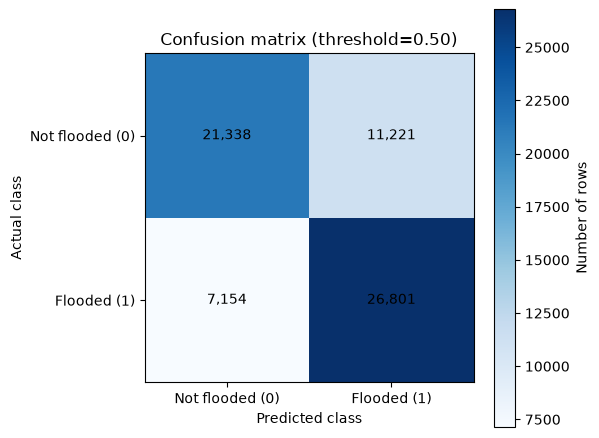

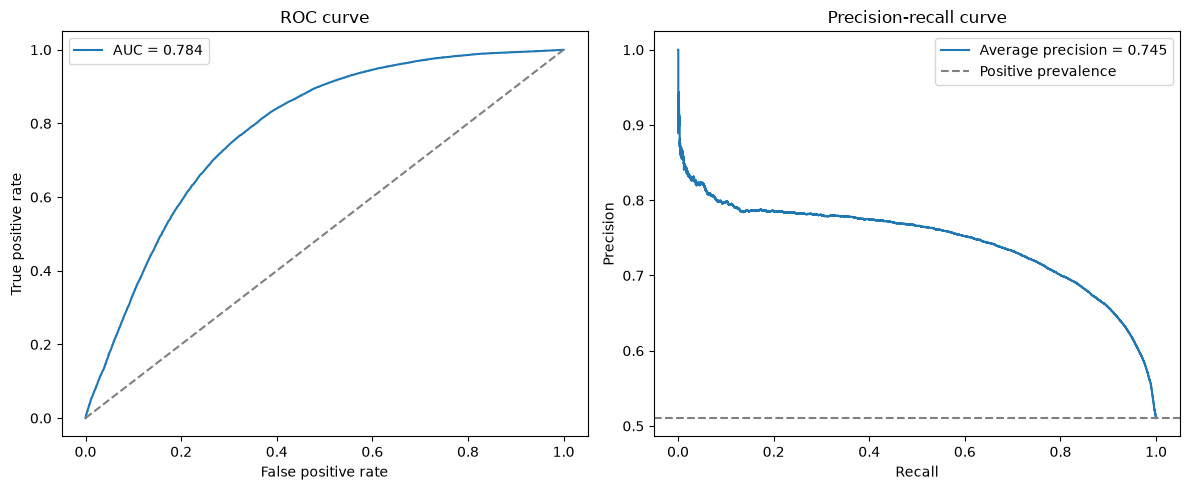

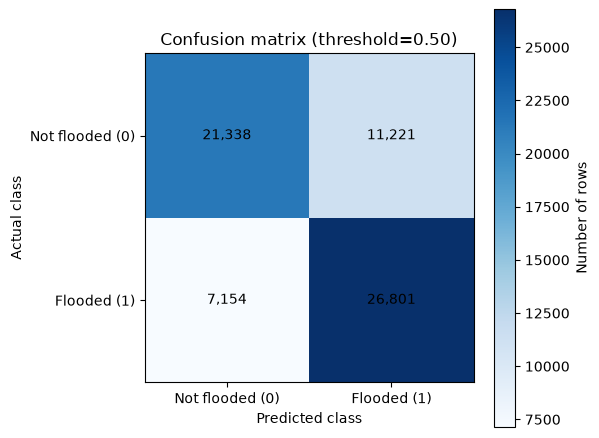

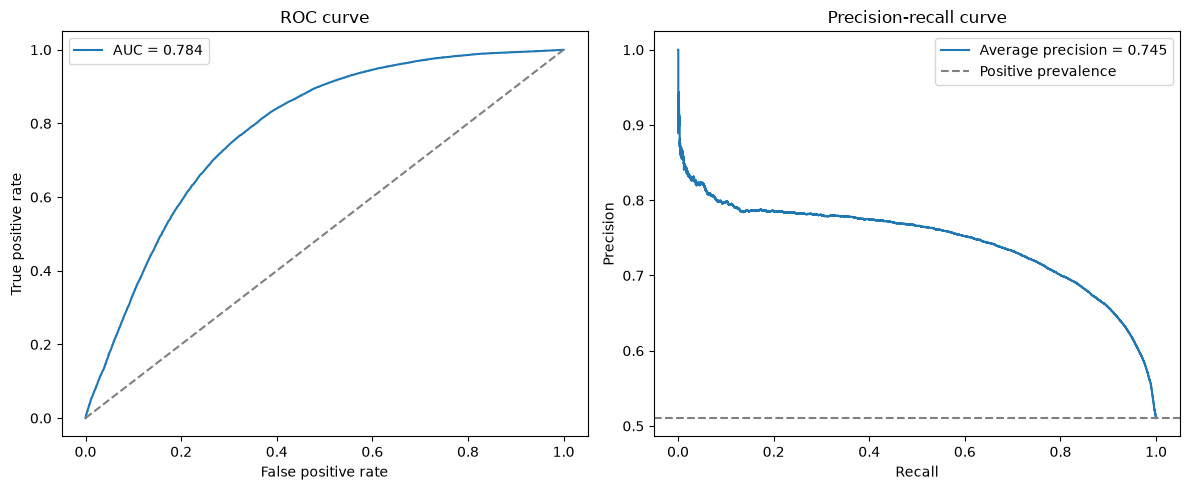

In [5]:
logistic_area_oof = evaluation_results[("logistic_regression", "area_group")][1]
confusion_figure = plot_confusion_matrix(logistic_area_oof, threshold=0.5)
roc_pr_figure = plot_roc_pr(logistic_area_oof)
display(confusion_figure)
display(roc_pr_figure)


**My observations:** _Describe which class errors dominate at threshold 0.5 and compare the ROC and precision-recall curve behavior._